In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the feature-engineered dataset
df = pd.read_csv("../data/processed/orders_prepared.csv")

print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

print("\nCountry distribution:")
print(df["Country/Region"].value_counts(dropna=False))


Dataset shape: (10194, 24)

Available columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Shipping Lead Time', 'Order ID Year', 'Adjusted Lead Time', 'Factory', 'Factory Latitude', 'Factory Longitude']

Country distribution:
Country/Region
United States    9994
Canada            200
Name: count, dtype: int64


## Route Definition & Aggregation

A route is defined as a factory associated with a customer destination, represented by the customer country, region, and state/province. Orders are grouped by these geographic attributes to measure route-level activity.

For each route, the following metrics will be calculated:
- **Total shipments:** Number of unique orders associated with the route, used as a shipment proxy.
- **Average shipping lead time:** Mean recorded time between order and ship dates.
- **Lead time variability:** Standard deviation of recorded shipping lead times.

*Note: An order may contain products assigned to different factories, so unique orders are used as a proxy for shipments rather than a verified count of physical shipments.*

In [2]:
# Step 1: Create a route identifier for each order line
df["Route"] = (
    df["Factory"].astype(str) + " → " +
    df["Country/Region"].astype(str) + " → " +
    df["Region"].astype(str) + " → " +
    df["State/Province"].astype(str)
)

# Step 2: Extract the unique routes present in the dataset
unique_routes = df["Route"].unique()

print("Total number of unique routes:", len(unique_routes))

Total number of unique routes: 196


In [3]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Units,Gross Profit,Cost,Shipping Lead Time,Order ID Year,Adjusted Lead Time,Factory,Factory Latitude,Factory Longitude,Route
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,2,4.22,2.28,909,2021,179,Wicked Choccy's,32.076176,-81.088371,Wicked Choccy's → United States → Interior → T...
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,2,4.90,2.60,909,2021,179,Wicked Choccy's,32.076176,-81.088371,Wicked Choccy's → United States → Interior → I...
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,3,7.47,3.00,909,2021,179,Lot's O' Nuts,32.881893,-111.768036,Lot's O' Nuts → United States → Interior → Ill...
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,3,7.50,3.30,909,2021,179,Lot's O' Nuts,32.881893,-111.768036,Lot's O' Nuts → United States → Interior → Ill...
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,3,7.35,3.90,912,2021,182,Wicked Choccy's,32.076176,-81.088371,Wicked Choccy's → United States → Atlantic → P...


In [4]:
route_shipments = (
    df.groupby("Route")
    .agg(
        Total_Shipments=("Order ID", "nunique")
    )
    .reset_index()
    .sort_values("Total_Shipments", ascending=False)
)

print("Number of routes:", len(route_shipments))

display(route_shipments.head(20))

Number of routes: 196


,Route,Total_Shipments
47,Lot's O' Nuts → United States → Pacific → Cali...,944
187,Wicked Choccy's → United States → Pacific → Ca...,689
16,Lot's O' Nuts → United States → Atlantic → New...,544
44,Lot's O' Nuts → United States → Interior → Texas,479
156,Wicked Choccy's → United States → Atlantic → N...,353
184,Wicked Choccy's → United States → Interior → T...,326
18,Lot's O' Nuts → United States → Atlantic → Pen...,270
33,Lot's O' Nuts → United States → Interior → Ill...,235
55,Lot's O' Nuts → United States → Pacific → Wash...,230
17,Lot's O' Nuts → United States → Atlantic → Ohio,218


In [5]:
# Validate route counts
print("Unique routes:", df["Route"].nunique())
print("Rows in route summary:", len(route_shipments))
print("Unique orders in original dataset:", df["Order ID"].nunique())

# Check for duplicate routes in the summary
print(
    "Duplicate routes in summary:",
    route_shipments["Route"].duplicated().sum()
)

# Check the highest-volume route directly
top_route = route_shipments.iloc[0]["Route"]

print("\nTop route:", top_route)
print(
    "Unique orders on top route:",
    df.loc[df["Route"] == top_route, "Order ID"].nunique()
)

Unique routes: 196
Rows in route summary: 196
Unique orders in original dataset: 8549
Duplicate routes in summary: 0

Top route: Lot's O' Nuts → United States → Pacific → California
Unique orders on top route: 944


In [6]:
# Calculate lead-time metrics for each route

route_lead_time = (
    df.groupby("Route")
    .agg(
        Total_Shipments=("Order ID", "nunique"),
        Average_Lead_Time=("Shipping Lead Time", "mean"),
        Median_Lead_Time=("Shipping Lead Time", "median"),
        Lead_Time_Std=("Shipping Lead Time", "std")
    )
    .reset_index()
)

# Sort by shipment volume
route_lead_time = route_lead_time.sort_values(
    by="Total_Shipments",
    ascending=False
)

# Round lead-time metrics to 2 decimal places
lead_time_columns = [
    "Average_Lead_Time",
    "Median_Lead_Time",
    "Lead_Time_Std"
]

route_lead_time[lead_time_columns] = (
    route_lead_time[lead_time_columns].round(2)
)

print("Total routes analysed:", len(route_lead_time))
display(route_lead_time.head(20))

Total routes analysed: 196


,Route,Total_Shipments,Average_Lead_Time,Median_Lead_Time,Lead_Time_Std
47,Lot's O' Nuts → United States → Pacific → Cali...,944,1316.91,1274.0,265.37
187,Wicked Choccy's → United States → Pacific → Ca...,689,1320.33,1274.0,262.50
16,Lot's O' Nuts → United States → Atlantic → New...,544,1330.52,1274.0,249.26
44,Lot's O' Nuts → United States → Interior → Texas,479,1310.46,1273.0,260.34
156,Wicked Choccy's → United States → Atlantic → N...,353,1311.88,1274.0,245.01
184,Wicked Choccy's → United States → Interior → T...,326,1315.61,1274.0,272.94
18,Lot's O' Nuts → United States → Atlantic → Pen...,270,1315.06,1273.0,260.48
33,Lot's O' Nuts → United States → Interior → Ill...,235,1319.93,1274.0,268.39
55,Lot's O' Nuts → United States → Pacific → Wash...,230,1343.96,1274.0,274.98
17,Lot's O' Nuts → United States → Atlantic → Ohio,218,1334.11,1273.0,260.44


In [7]:
# Calculate adjusted lead-time metrics for each route

route_lead_time = (
    df.groupby("Route")
    .agg(
        Total_Shipments=("Order ID", "nunique"),
        Average_Lead_Time=("Adjusted Lead Time", "mean"),
        Median_Lead_Time=("Adjusted Lead Time", "median"),
        Lead_Time_Std=("Adjusted Lead Time", "std")
    )
    .reset_index()
)

# Round metrics for readability
lead_time_columns = [
    "Average_Lead_Time",
    "Median_Lead_Time",
    "Lead_Time_Std"
]

route_lead_time[lead_time_columns] = (
    route_lead_time[lead_time_columns].round(2)
)

# Sort routes by shipment volume
route_lead_time = route_lead_time.sort_values(
    by="Total_Shipments",
    ascending=False
).reset_index(drop=True)

print("Total unique routes:", len(route_lead_time))
display(route_lead_time.head(20))

Total unique routes: 196


,Route,Total_Shipments,Average_Lead_Time,Median_Lead_Time,Lead_Time_Std
0,Lot's O' Nuts → United States → Pacific → Cali...,944,177.41,178.0,1.91
1,Wicked Choccy's → United States → Pacific → Ca...,689,177.61,178.0,1.84
2,Lot's O' Nuts → United States → Atlantic → New...,544,177.64,178.0,1.81
3,Lot's O' Nuts → United States → Interior → Texas,479,177.57,178.0,1.73
4,Wicked Choccy's → United States → Atlantic → N...,353,177.65,178.0,1.85
5,Wicked Choccy's → United States → Interior → T...,326,177.63,178.0,1.82
6,Lot's O' Nuts → United States → Atlantic → Pen...,270,177.51,178.0,1.53
7,Lot's O' Nuts → United States → Interior → Ill...,235,177.76,178.0,1.59
8,Lot's O' Nuts → United States → Pacific → Wash...,230,177.67,178.0,1.88
9,Lot's O' Nuts → United States → Atlantic → Ohio,218,177.08,177.0,2.05


In [8]:
# Validate the adjusted lead-time distribution

print("Adjusted lead-time summary:")
display(df["Adjusted Lead Time"].describe().to_frame().round(2))

print("\nMost frequent adjusted lead times:")
display(
    df["Adjusted Lead Time"]
    .value_counts()
    .sort_index()
    .rename_axis("Adjusted_Lead_Time")
    .reset_index(name="Frequency")
    .sort_values("Frequency", ascending=False)
    .head(15)
)

print(
    "\nMissing adjusted lead times:",
    df["Adjusted Lead Time"].isna().sum()
)

print(
    "Non-positive adjusted lead times:",
    (df["Adjusted Lead Time"] <= 0).sum()
)

Adjusted lead-time summary:


,Adjusted Lead Time
count,10194.00
mean,177.59
std,1.82
min,173.00
25%,176.00
50%,178.00
75%,179.00
max,185.00



Most frequent adjusted lead times:


,Adjusted_Lead_Time,Frequency
5,178,2573
6,179,1894
4,177,1728
3,176,1212
7,180,967
2,175,750
1,174,434
8,181,392
0,173,220
9,182,22



Missing adjusted lead times: 0
Non-positive adjusted lead times: 0


In [9]:
# Calculate lead-time variability for each route

route_variability = (
    df.groupby("Route")
    .agg(
        Total_Orders=("Order ID", "nunique"),
        Mean_Lead_Time=("Adjusted Lead Time", "mean"),
        Std_Lead_Time=("Adjusted Lead Time", "std"),
        Min_Lead_Time=("Adjusted Lead Time", "min"),
        Max_Lead_Time=("Adjusted Lead Time", "max")
    )
    .reset_index()
)

# Calculate the range of lead times
route_variability["Lead_Time_Range"] = (
    route_variability["Max_Lead_Time"]
    - route_variability["Min_Lead_Time"]
)

# Calculate coefficient of variation (CV) as a percentage
route_variability["Lead_Time_CV_Percent"] = (
    route_variability["Std_Lead_Time"]
    / route_variability["Mean_Lead_Time"]
) * 100

# Round numeric metrics
numeric_cols = route_variability.select_dtypes(include="number").columns
route_variability[numeric_cols] = route_variability[numeric_cols].round(2)

# Display routes with the highest variability first
route_variability = route_variability.sort_values(
    by="Std_Lead_Time",
    ascending=False
).reset_index(drop=True)

display(route_variability.head(20))

,Route,Total_Orders,Mean_Lead_Time,Std_Lead_Time,Min_Lead_Time,Max_Lead_Time,Lead_Time_Range,Lead_Time_CV_Percent
0,Sugar Shack → United States → Atlantic → Ohio,2,176.50,3.54,174,179,5,2.00
1,Secret Factory → United States → Gulf → North ...,4,178.25,3.10,174,181,7,1.74
2,Lot's O' Nuts → Canada → Atlantic → Newfoundla...,5,181.50,2.95,178,185,7,1.63
3,Secret Factory → United States → Pacific → Nevada,2,178.00,2.83,176,180,4,1.59
4,Secret Factory → United States → Pacific → New...,2,176.00,2.83,174,178,4,1.61
5,The Other Factory → United States → Atlantic →...,2,178.00,2.83,176,180,4,1.59
6,Lot's O' Nuts → United States → Atlantic → Wes...,2,176.00,2.83,174,178,4,1.61
7,The Other Factory → United States → Gulf → Ten...,3,178.00,2.65,175,180,5,1.49
8,Wicked Choccy's → United States → Pacific → Mo...,5,178.57,2.64,174,181,7,1.48
9,Secret Factory → United States → Interior → Mi...,5,177.40,2.51,173,179,6,1.41


In [10]:
# Compare variability for routes with at least 30 unique orders

reliable_routes = route_variability[
    route_variability["Total_Orders"] >= 30
].copy()

# 10 routes with the highest variability
most_variable_routes = reliable_routes.nlargest(
    10, "Std_Lead_Time"
)

# 10 routes with the lowest variability
least_variable_routes = reliable_routes.nsmallest(
    10, "Std_Lead_Time"
)

print("Top 10 most variable routes (minimum 30 orders):")
display(most_variable_routes)

print("\nTop 10 least variable routes (minimum 30 orders):")
display(least_variable_routes)

Top 10 most variable routes (minimum 30 orders):


,Route,Total_Orders,Mean_Lead_Time,Std_Lead_Time,Min_Lead_Time,Max_Lead_Time,Lead_Time_Range,Lead_Time_CV_Percent
10,Wicked Choccy's → United States → Atlantic → C...,30,177.26,2.45,173,181,8,1.38
19,Lot's O' Nuts → United States → Atlantic → Con...,40,177.17,2.12,173,180,7,1.20
29,Wicked Choccy's → United States → Interior → M...,36,178.40,2.09,174,181,7,1.17
32,Lot's O' Nuts → United States → Gulf → Georgia,88,177.44,2.07,173,181,8,1.16
33,Lot's O' Nuts → United States → Interior → Okl...,34,177.98,2.06,173,181,8,1.15
35,Lot's O' Nuts → United States → Atlantic → Del...,39,177.70,2.06,173,182,9,1.16
36,Lot's O' Nuts → United States → Atlantic → Ohio,218,177.08,2.05,173,182,9,1.16
37,Wicked Choccy's → United States → Gulf → Georgia,55,177.48,2.03,173,181,8,1.14
38,Wicked Choccy's → United States → Pacific → Ar...,88,177.80,2.03,173,181,8,1.14
39,Wicked Choccy's → United States → Atlantic → Ohio,157,177.11,2.02,173,182,9,1.14



Top 10 least variable routes (minimum 30 orders):


,Route,Total_Orders,Mean_Lead_Time,Std_Lead_Time,Min_Lead_Time,Max_Lead_Time,Lead_Time_Range,Lead_Time_CV_Percent
118,Wicked Choccy's → United States → Atlantic → M...,43,177.91,1.31,174,181,7,0.73
117,Wicked Choccy's → United States → Pacific → Co...,49,177.16,1.34,174,180,6,0.75
113,Lot's O' Nuts → United States → Interior → Mis...,30,177.83,1.40,174,180,6,0.79
110,Wicked Choccy's → United States → Gulf → Tenne...,56,178.12,1.42,175,181,6,0.80
105,Lot's O' Nuts → United States → Interior → Min...,38,178.30,1.46,175,181,6,0.82
99,Lot's O' Nuts → United States → Atlantic → Pen...,270,177.51,1.53,173,181,8,0.86
95,Wicked Choccy's → United States → Gulf → Kentucky,45,177.79,1.58,174,181,7,0.89
97,Wicked Choccy's → United States → Interior → W...,42,177.66,1.58,173,180,7,0.89
94,Lot's O' Nuts → United States → Interior → Ill...,235,177.76,1.59,173,182,9,0.89
91,Lot's O' Nuts → United States → Gulf → Tennessee,88,177.94,1.60,174,181,7,0.90


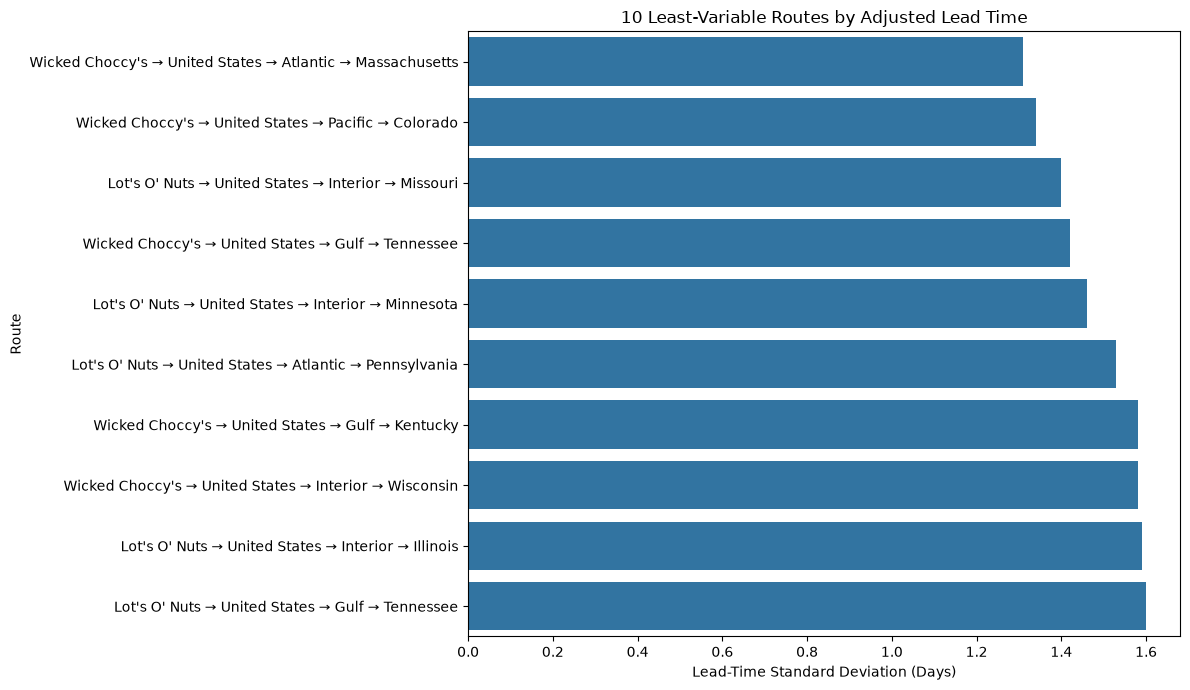

In [11]:
# Visualise the 10 least-variable routes

plot_data = least_variable_routes.sort_values(
    "Std_Lead_Time", ascending=True
).copy()

plt.figure(figsize=(12, 7))

sns.barplot(
    data=plot_data,
    x="Std_Lead_Time",
    y="Route"
)

plt.title("10 Least-Variable Routes by Adjusted Lead Time")
plt.xlabel("Lead-Time Standard Deviation (Days)")
plt.ylabel("Route")
plt.tight_layout()
plt.show()

In [12]:
# Lead Time Variability: Complete Route-Level Metrics

route_variability = (
    df.groupby("Route")
    .agg(
        Total_Orders=("Order ID", "nunique"),
        Mean_Lead_Time=("Adjusted Lead Time", "mean"),
        Median_Lead_Time=("Adjusted Lead Time", "median"),
        Std_Lead_Time=("Adjusted Lead Time", "std"),
        Min_Lead_Time=("Adjusted Lead Time", "min"),
        Max_Lead_Time=("Adjusted Lead Time", "max")
    )
    .reset_index()
)

# Calculate additional variability metrics
route_variability["Lead_Time_Range"] = (
    route_variability["Max_Lead_Time"]
    - route_variability["Min_Lead_Time"]
)

route_variability["Lead_Time_CV_Percent"] = (
    route_variability["Std_Lead_Time"]
    / route_variability["Mean_Lead_Time"]
) * 100

# Round numerical metrics
numeric_cols = route_variability.select_dtypes(
    include="number"
).columns

route_variability[numeric_cols] = (
    route_variability[numeric_cols].round(2)
)

# Exclude routes with fewer than 30 orders for fairer comparison
eligible_routes = route_variability[
    route_variability["Total_Orders"] >= 30
].copy()

# 10 most-variable routes
most_variable_routes = eligible_routes.nlargest(
    10, "Std_Lead_Time"
)

# 10 least-variable routes
least_variable_routes = eligible_routes.nsmallest(
    10, "Std_Lead_Time"
)

print("Total unique routes:", len(route_variability))
print("Routes with at least 30 orders:", len(eligible_routes))

print("\n10 MOST VARIABLE ROUTES")
display(most_variable_routes)

print("\n10 LEAST VARIABLE ROUTES")
display(least_variable_routes)

Total unique routes: 196
Routes with at least 30 orders: 54

10 MOST VARIABLE ROUTES


,Route,Total_Orders,Mean_Lead_Time,Median_Lead_Time,Std_Lead_Time,Min_Lead_Time,Max_Lead_Time,Lead_Time_Range,Lead_Time_CV_Percent
148,Wicked Choccy's → United States → Atlantic → C...,30,177.26,177.0,2.45,173,181,8,1.38
8,Lot's O' Nuts → United States → Atlantic → Con...,40,177.17,177.0,2.12,173,180,7,1.20
178,Wicked Choccy's → United States → Interior → M...,36,178.40,179.0,2.09,174,181,7,1.17
25,Lot's O' Nuts → United States → Gulf → Georgia,88,177.44,178.0,2.07,173,181,8,1.16
9,Lot's O' Nuts → United States → Atlantic → Del...,39,177.70,178.0,2.06,173,182,9,1.16
42,Lot's O' Nuts → United States → Interior → Okl...,34,177.98,179.0,2.06,173,181,8,1.15
17,Lot's O' Nuts → United States → Atlantic → Ohio,218,177.08,177.0,2.05,173,182,9,1.16
165,Wicked Choccy's → United States → Gulf → Georgia,55,177.48,178.0,2.03,173,181,8,1.14
186,Wicked Choccy's → United States → Pacific → Ar...,88,177.80,178.0,2.03,173,181,8,1.14
157,Wicked Choccy's → United States → Atlantic → Ohio,157,177.11,177.0,2.02,173,182,9,1.14



10 LEAST VARIABLE ROUTES


,Route,Total_Orders,Mean_Lead_Time,Median_Lead_Time,Std_Lead_Time,Min_Lead_Time,Max_Lead_Time,Lead_Time_Range,Lead_Time_CV_Percent
153,Wicked Choccy's → United States → Atlantic → M...,43,177.91,178.0,1.31,174,181,7,0.73
188,Wicked Choccy's → United States → Pacific → Co...,49,177.16,177.0,1.34,174,180,6,0.75
39,Lot's O' Nuts → United States → Interior → Mis...,30,177.83,178.0,1.40,174,180,6,0.79
171,Wicked Choccy's → United States → Gulf → Tenne...,56,178.12,178.0,1.42,175,181,6,0.80
38,Lot's O' Nuts → United States → Interior → Min...,38,178.30,178.0,1.46,175,181,6,0.82
18,Lot's O' Nuts → United States → Atlantic → Pen...,270,177.51,178.0,1.53,173,181,8,0.86
166,Wicked Choccy's → United States → Gulf → Kentucky,45,177.79,178.0,1.58,174,181,7,0.89
185,Wicked Choccy's → United States → Interior → W...,42,177.66,178.0,1.58,173,180,7,0.89
33,Lot's O' Nuts → United States → Interior → Ill...,235,177.76,178.0,1.59,173,182,9,0.89
31,Lot's O' Nuts → United States → Gulf → Tennessee,88,177.94,178.0,1.60,174,181,7,0.90


In [13]:
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Validate adjusted lead-time values
lead_time = pd.to_numeric(df["Adjusted Lead Time"], errors="coerce")

print("Total rows:", len(df))
print("Missing adjusted lead times:", lead_time.isna().sum())
print("Non-positive adjusted lead times:", (lead_time <= 0).sum())
print("Unique routes:", df["Route"].nunique())

# 2. Recalculate final route-level metrics
route_summary = (
    df.groupby("Route")
    .agg(
        Total_Orders=("Order ID", "nunique"),
        Mean_Lead_Time=("Adjusted Lead Time", "mean"),
        Median_Lead_Time=("Adjusted Lead Time", "median"),
        Std_Lead_Time=("Adjusted Lead Time", "std"),
        Min_Lead_Time=("Adjusted Lead Time", "min"),
        Max_Lead_Time=("Adjusted Lead Time", "max")
    )
    .reset_index()
)

route_summary["Lead_Time_Range"] = (
    route_summary["Max_Lead_Time"] - route_summary["Min_Lead_Time"]
)

route_summary["Lead_Time_CV_Percent"] = (
    route_summary["Std_Lead_Time"]
    / route_summary["Mean_Lead_Time"].replace(0, np.nan)
) * 100

# Round metrics
numeric_cols = route_summary.select_dtypes(include="number").columns
route_summary[numeric_cols] = route_summary[numeric_cols].round(2)

# 3. Run structural checks
assert route_summary["Route"].is_unique, "Duplicate routes found!"
assert len(route_summary) == df["Route"].nunique(), "Route count mismatch!"

print("\nRoutes in final summary:", len(route_summary))
print("Duplicate routes:", route_summary["Route"].duplicated().sum())

# 4. Save the final summary
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "route_level_summary.csv"
route_summary.to_csv(output_path, index=False)

print("\nSaved to:", output_path)
display(route_summary.head())

Total rows: 10194
Missing adjusted lead times: 0
Non-positive adjusted lead times: 0
Unique routes: 196

Routes in final summary: 196
Duplicate routes: 0

Saved to: ..\data\processed\route_level_summary.csv


,Route,Total_Orders,Mean_Lead_Time,Median_Lead_Time,Std_Lead_Time,Min_Lead_Time,Max_Lead_Time,Lead_Time_Range,Lead_Time_CV_Percent
0,Lot's O' Nuts → Canada → Atlantic → New Brunswick,4,177.50,177.5,0.58,177,178,1,0.33
1,Lot's O' Nuts → Canada → Atlantic → Newfoundla...,5,181.50,181.0,2.95,178,185,7,1.63
2,Lot's O' Nuts → Canada → Atlantic → Ontario,24,176.86,176.0,1.38,175,179,4,0.78
3,Lot's O' Nuts → Canada → Atlantic → Prince Edw...,6,178.33,178.0,0.52,178,179,1,0.29
4,Lot's O' Nuts → Canada → Atlantic → Quebec,20,177.54,178.0,2.06,174,181,7,1.16
